# Qiskit 入門ハンズオン

Kifumi Numata, IBM Quantum (Nov 26, 2026)

コードセルは、セルを選択して「Shift」＋「Enter」、または上部の三角アイコンをクリックすると実行できます。

In [ ]:
#%pip install "python-dateutil>=2.8.2,<3" "qiskit[visualization]" qiskit-ibm-runtime qiskit-aer

In [ ]:
# Qiskitバージョンの確認
import qiskit
qiskit.__version__

### 目次:
1. 単一量子ビット回路
2. 測定
3. 複数量子ビット回路ともつれ状態
4. 量子テレポーテーション
付録. 実機での実行

# 1. 単一量子ビット回路

### 空の回路
1量子ビットの回路を作成し、描画します。

In [ ]:
from qiskit import QuantumCircuit
# １量子ビット回路を用意
qc = QuantumCircuit(1)

# 回路を描画
qc.draw(output="mpl")

In [ ]:
# 状態ベクトルシミュレーターの実行
from qiskit.quantum_info import Statevector
sv = Statevector(qc)
print(sv)

# ブロッホ球の表示
from qiskit.visualization import plot_bloch_multivector
plot_bloch_multivector(sv)

縦ベクトルが横ベクトル表示で、複素数(虚部の添字は j )で表示されています。</br>
IBM Quantumでは、初期状態は$|0\rangle$にセットされていますので、上記の量子回路の状態は、ベクトル表示で$ \begin{pmatrix}
1 \\
0
\end{pmatrix}$となっていて、ブロッホ球上でも$|0\rangle$になっていることがわかります。

### Xゲート
Xゲートはブロッホ球の$x$軸周りの$\pi$回転です。
$|0\rangle$にXゲートを適用すると$|1\rangle$、$|1\rangle$にXゲートを適用すると$|0\rangle$になるので、古典のNOTゲートのような操作が実現でき、ビット反転とも呼ばれます。

$X = \begin{pmatrix}
0 & 1 \\
1 & 0 \\
\end{pmatrix}$

In [ ]:
qc = QuantumCircuit(1)    # １量子ビット回路を用意

# Xゲートを0番目の量子ビットに操作します。
qc.x(0)

# 回路を描画
qc.draw(output="mpl")

上記の量子回路の状態は、行列ベクトル表示では

$X|0\rangle=  \begin{pmatrix}
0 & 1 \\\
1 & 0
\end{pmatrix} 
\begin{pmatrix}
1 \\\
0
\end{pmatrix} 
 =\begin{pmatrix}
0 \\\
1
\end{pmatrix} = |1\rangle$ 

となります。次にこの回路の出力ベクトルを状態ベクトルシミュレーターを使って実行してみます。

In [ ]:
# 状態ベクトルシミュレーターの実行
sv = Statevector(qc)
print(sv)

# ブロッホ球の表示
plot_bloch_multivector(sv)

### Hゲート

Hadamardゲート(アダマールゲート)はブロッホ球の$x$軸と$z$軸の中間の軸周りの$\pi$回転です。
例えば$|0\rangle$にHゲートを適用すると、$\frac{|0\rangle + |1\rangle}{\sqrt{2}}$のような重ね合わせ状態を作ることができます。

$H = \frac{1}{\sqrt{2}}\begin{pmatrix}
1 & 1 \\
1 & -1 \\
\end{pmatrix}$

In [ ]:
qc = QuantumCircuit(1)    # １量子ビット回路を用意 

# Hゲートを0番目の量子ビットに操作します。
qc.h(0)

# 回路を描画
qc.draw(output="mpl")

In [ ]:
# 状態ベクトルシミュレーターの実行
sv = Statevector(qc)
print(sv)

# ブロッホ球の表示
plot_bloch_multivector(sv)

これは、$H|0\rangle= \frac{1}{\sqrt{2}} \begin{pmatrix}
1 & 1 \\\
1 & -1
\end{pmatrix} 
\begin{pmatrix}
1 \\\
0
\end{pmatrix} 
 =\frac{1}{\sqrt{2}}\begin{pmatrix}
1 \\\
1
\end{pmatrix} 
=\begin{pmatrix}
0.707\cdot\cdot\cdot \\\
0.707\cdot\cdot\cdot
\end{pmatrix} 
=\frac{1}{\sqrt{2}}(|0\rangle+|1\rangle)=|+\rangle$ です。




$H$ゲートを$|0\rangle$に実行すると、$|0\rangle$と$|1\rangle$の均等な重ね合わせ状態が作れることが分かります。この状態は$|+\rangle$とも呼ばれます。


### $|-\rangle$状態

In [ ]:
qc = QuantumCircuit(1)    # １量子ビット回路を用意 

# Xゲートを0番目の量子ビットに操作します。
qc.x(0)

# 次にHゲートを0番目の量子ビットに操作します。
qc.h(0)

# 回路を描画
qc.draw(output="mpl")

In [ ]:
# 状態ベクトルシミュレーターの実行
sv = Statevector(qc)
print(sv)

# ブロッホ球の表示
plot_bloch_multivector(sv)

$H|1\rangle= \frac{1}{\sqrt{2}} \begin{pmatrix}
1 & 1 \\\
1 & -1
\end{pmatrix} 
\begin{pmatrix}
0 \\\
1
\end{pmatrix} 
 =\frac{1}{\sqrt{2}}\begin{pmatrix}
1 \\\
-1
\end{pmatrix} 
=\begin{pmatrix}
0.707\cdot\cdot\cdot \\\
-0.707\cdot\cdot\cdot
\end{pmatrix} 
=\frac{1}{\sqrt{2}}(|0\rangle-|1\rangle)=|-\rangle$


$|1\rangle$に$H$ゲートを実行した結果、$|0\rangle$と$|1\rangle$の均等な重ね合わせ状態になりますが、$|1\rangle$の符号がマイナスになります。この状態は$|-\rangle$とも呼ばれます。

### その他の1量子ビットゲート

そのほかの代表的な1量子ビットゲートをこちらで確認してみましょう：https://javafxpert.github.io/grok-bloch/

## 演習1
次の量子回路をプログラミングし、状態ベクトルシミュレーターで実行して、ブロッホ球を表示してみましょう。

(1) $XX|0\rangle$

(2) $HH|0\rangle$  

(3) $ZH|1\rangle$

ヒント：Zゲートはブロッホ球の$z$軸周りの$\pi$回転です。位相反転とも呼ばれ、`qc.z(0)` のようにコーデイングします。

$Z = \begin{pmatrix}
1 & 0 \\
0 & -1 \\
\end{pmatrix}$


In [ ]:
### (1) XX|0> ###

# １量子ビット回路を用意 
qc = ##コードを記入します##

# Xゲートを0番目の量子ビットに操作します。
qc.##コードを記入します##

# もう一度、Xゲートを0番目の量子ビットに操作します。
qc.##コードを記入します##

# 回路を描画
qc.draw(output="mpl")

In [ ]:
# 状態ベクトルシミュレーターの実行
sv = Statevector(qc)
print(sv)

# ブロッホ球の表示
plot_bloch_multivector(sv)

In [ ]:
### (2) HH|0> ###
##コードを記入します##





In [ ]:
# 状態ベクトルシミュレーターの実行
sv = Statevector(qc)
print(sv)

# ブロッホ球の表示
plot_bloch_multivector(sv)

In [ ]:
### (3) ZH|1> ###
##コードを記入します##





In [ ]:
# 状態ベクトルシミュレーターの実行
sv = Statevector(qc)
print(sv)

# ブロッホ球の表示
plot_bloch_multivector(sv)

# 2. 測定

量子ビット $|\psi\rangle=\alpha|0\rangle+\beta|1\rangle$ は観測することによって、 $|0\rangle$または$|1\rangle$へ状態が変わります。一般的な計算基底で測定を行うと、$|0\rangle$を得る確率は、$|\alpha|^2$ であり、$|1\rangle$を得る確率は、$|\beta|^2$ です（ボルンの法則）。

例えば、$|\psi\rangle=\frac{1}{\sqrt{2}}(|0\rangle+|1\rangle)$ を測定すると、$\frac{1}{2}$の確率で$|0\rangle$が測定（$\frac{1}{2}$の確率で$|1\rangle$が測定）されます。

測定するためには量子回路に測定ゲートを追加します。

In [ ]:
qc = QuantumCircuit(1,1) # 1量子ビットと1古典ビットの回路を作成します。
qc.h(0)
qc.measure(0,0) # 測定ゲートを追加

qc.draw(output="mpl")

[Qiskit Primitive](https://quantum.cloud.ibm.com/docs/guides/primitives)のSamplerで量子回路の出力をサンプリングします。実際の量子コンピューターで計算する前に、シミュレーター版の [StatevectorSampler](https://quantum.cloud.ibm.com/docs/ja/guides/simulate-with-qiskit-sdk-primitives#use-the-reference-sampler) を使ってみましょう。
1024回実行した結果、それぞれの状態が測定された回数を表示し、その測定結果をヒストグラムで表示します。

In [ ]:
# シミュレーター版のSampler
from qiskit.primitives import StatevectorSampler
sampler_sim = StatevectorSampler()

In [ ]:
# シミュレーターで実験
job = sampler_sim.run([qc]) # デフォルトのshot数は1024です
result = job.result()

# 測定された回数を表示
counts = result[0].data.c.get_counts()
print(counts)

# ヒストグラムで測定された回数をプロット
from qiskit.visualization import plot_histogram
plot_histogram(counts)

ほぼ50％ずつの確率で0と1が測定されることが確認できました。

# 3. 複数量子ビット回路ともつれ状態

## 3.1 複数量子ビット回路

In [ ]:
# ２量子ビット回路を作成します。
qc = QuantumCircuit(2)

# Hゲートを0番目の量子ビットに操作します。
qc.h(0)

# Hゲートを1番目の量子ビットに操作します。
qc.h(1)

# 回路を描画
qc.draw(output="mpl")

In [ ]:
# 状態ベクトルシミュレーターの実行
sv = Statevector(qc)
print(sv)

2量子ビットの状態は、1量子ビットの積（テンソル積）で表せます。

$|\psi\rangle=|q0\rangle \otimes|q1\rangle = (a|0\rangle+b|1\rangle) \otimes (c|0\rangle+d|1\rangle) $

$= ac|0\rangle|0\rangle+ad|0\rangle|1\rangle+bc|1\rangle|0\rangle+bd|1\rangle|1\rangle$

$= ac|00\rangle+ad|01\rangle+bc|10\rangle+bd|11\rangle$

(ただし、$|ac|^2+ |ad|^2+ |bc|^2+ |bd|^2=1$ )


Qiskitの初期値は、$|00\rangle=|0\rangle\otimes|0\rangle$なので、$H$をそれぞれの量子ビットに操作させることで均等な重ね合わせの状態になります。

$H|0\rangle \otimes H|0\rangle=\frac{1}{\sqrt{2}}(|0\rangle+|1\rangle) \otimes \frac{1}{\sqrt{2}}(|0\rangle+|1\rangle) = \frac{1}{2}(|00\rangle+|01\rangle+|10\rangle+|11\rangle)$

$$ 
=\frac{1}{2}\left( \begin{pmatrix} 1 \\ 1 \end{pmatrix} \otimes \begin{pmatrix} 1 \\ 1 \end{pmatrix}\right) = \frac{1}{2}\begin{pmatrix} 1 \\ 1 \\ 1 \\ 1 \end{pmatrix}=\frac{1}{2}\left(\begin{pmatrix} 1 \\ 0 \\ 0 \\ 0 \end{pmatrix}+\begin{pmatrix} 0 \\ 1 \\ 0 \\ 0 \end{pmatrix}+\begin{pmatrix} 0 \\ 0 \\ 1 \\ 0 \end{pmatrix}+\begin{pmatrix} 0 \\ 0 \\ 0 \\ 1 \end{pmatrix}\right)
$$

測定のルールも1量子ビット状態の場合と同じで、例えば $|00\rangle$ を測定する確率は、$|ac|^2$です。

In [ ]:
# ブロッホ球の表示
plot_bloch_multivector(sv, figsize=(3,4))

次に、この状態を測定してみましょう。

まず、測定回路を追加します。

In [ ]:
# ２量子ビットと2古典ビットの回路を作成します。
qc = QuantumCircuit(2,2)

# ゲートを適用します。
qc.h(0)
qc.h(1)

# 測定ゲートを追加
qc.measure(0, 0)
qc.measure(1, 1)

# 回路を描画
qc.draw(output="mpl")

次にシミュレーター版のSamplerで実行します。1024回実行した結果、それぞれの状態が測定された回数とヒストグラムを表示します。

In [ ]:
# シミュレーター版のSamplerで実行
job = sampler_sim.run([qc]) # defoult shot number is 1024
result = job.result()

#  測定された回数を表示
counts = result[0].data.c.get_counts()
print(counts)

# ヒストグラムで測定された回数をプロット
plot_histogram(counts, figsize=(4, 3))

$|00\rangle$、$|01\rangle$、$|10\rangle$、$|11\rangle$の状態がほぼ25%ずつ均等に測定されました。

## 3.2 複数量子ゲート

代表的な複数量子ゲートである $CNOT$ゲート（$CX$ゲート）は、2量子ビットにかかる量子ゲートで、制御ビットが1のときのみ、目標ビットの値を反転します。　　　　
![image.png](https://github.com/kifumi/qiskit-handson/blob/main/2026/20261126_jaxa/figures/cnot_table.jpg)

以下の # をはずして結果を確認してみましょう。
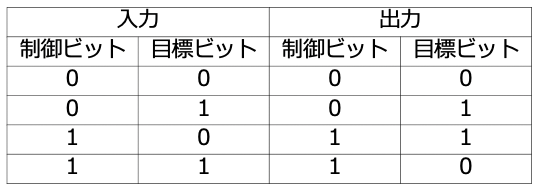

In [ ]:
# ２量子ビット回路を作成します。 
qc = QuantumCircuit(2,2)

#qc.x(0)
#qc.x(1)
qc.cx(0,1)   # CNOTゲートの制御ビットをq0、目標ビットをq1にセットします。

# 回路を描画
qc.draw(output="mpl")

In [ ]:
## 状態ベクトルシミュレーターの実行
sv = Statevector(qc)
print(sv)

In [ ]:
# 回路を測定
qc.measure(0, 0)
qc.measure(1, 1)

# シミュレーター版のSamplerで実行
job = sampler_sim.run([qc]) # defoult shot number is 1024
result = job.result()

#  測定された回数を表示
counts = result[0].data.c.get_counts()
print(counts)

# ヒストグラムで測定された回数をプロット
plot_histogram(counts, figsize=(4, 3))

## 3.3 量子もつれ

量子計算上でも重要な状態となる、量子もつれ状態（エンタングルメント状態）を生成してみましょう。

2量子ビットの量子もつれ状態の1つの例が次のような形になります。
$$\frac{1}{\sqrt{2}}|00\rangle + \frac{1}{\sqrt{2}}|11\rangle$$

これは、「片方の量子ビットが$|0\rangle$の場合に、もう片方の量子ビットも$|0\rangle$になっている」状態と、「片方の量子ビットが$|1\rangle$の場合に、もう片方の量子ビットも$|1\rangle$になっている」状態の重ね合わせ状態になっています。つまり、片方の量子ビットの状態が決まると、残りの量子ビットが確定するような状態となっています。別の言い方をすると、$|00\rangle$と$|11\rangle$という2つの状態が半々の確率で観測されることを示しています。

この状態は次のようにして作ることができます。まず片方の量子ビット($q_0$)に $H$ゲートをかけて重ね合わせの状態にします。

$$|00\rangle \to \frac{1}{\sqrt{2}}|00\rangle + \frac{1}{\sqrt{2}}|01\rangle$$

その後、CXゲートを作用させます。$q_0$をコントロールビット、$q_1$をターゲットビットとします。すると、右側が1の量子ビットに対して、残った方の量子ビットが反転します。

$$\frac{1}{\sqrt{2}}|00\rangle + \frac{1}{\sqrt{2}}|01\rangle \to \frac{1}{\sqrt{2}}|00\rangle + \frac{1}{\sqrt{2}}|11\rangle$$

では、演習2で実際にこの量子状態を作ってみましょう。<br>


## 演習2

(1) 次の回路をプログラミングし、Aerシミュレーターを実行して、結果をヒストグラムで表示してください。$|00\rangle$と$|11\rangle$がほぼ半分ずつになることを確認します。
![image.png](https://github.com/kifumi/qiskit-handson/blob/main/2026/20261126_jaxa/figures/bell_circuit.jpg)

In [ ]:
# 2量子ビット回路の用意
qc = ##コードを記入します##

# 2量子ビットのエンタングルメント回路の作成
qc.##コードを記入します##
qc.##コードを記入します##

# 回路を測定
qc.##コードを記入します##
qc.##コードを記入します## 

# 回路を描画
qc.draw(output="mpl")

In [ ]:
# シミュレーター版のSamplerで実行
job = sampler_sim.run([qc]) # defoult shot number is 1024
result = job.result()

#  測定された回数を表示
counts = result[0].data.c.get_counts()
print(counts)

# ヒストグラムで測定された回数をプロット
plot_histogram(counts, figsize=(4, 3))

# 4. 量子テレポーテーション

In [ ]:
import numpy as np
# 3量子ビット回路を用意
qc = QuantumCircuit(3,3)    

# Aliceのもつ暗号の量子状態ψを今回はRxで作ります
qc.rx(np.pi/3,0)
qc.barrier()    #回路を見やすくするために入れます

# 回路を描画
qc.draw(output="mpl")

In [ ]:
# Qiskit aerのStatevectorシミュレーターを使います
from qiskit_aer import StatevectorSimulator
backend = StatevectorSimulator()
result = backend.run(qc).result().get_statevector(qc, decimals=3)

from qiskit.visualization import plot_bloch_multivector
plot_bloch_multivector(result)

In [ ]:
# 量子もつれを作ります
qc.h(1)
qc.cx(1, 2)
qc.barrier()    #回路を見やすくするために入れます

# 回路を描画
qc.draw(output="mpl")

In [ ]:
# AliceがCNOTとHで、自分の量子ビット2つをエンタングルさせ測定します。
qc.cx(0, 1)
qc.h(0)
qc.barrier()

qc.measure(0, 0)
qc.measure(1, 1)

# 回路を描画
qc.draw(output="mpl")

In [ ]:
#Aliceが測定結果をBobに送り、Bobが結果に合わせて操作します
with qc.if_test((1, 1)): # 古典レジスター1の値が1だったらXゲートをq2にかける
    qc.x(2)
with qc.if_test((0, 1)): # 古典レジスター0の値が1だったらZゲートをq2にかける
    qc.z(2)    
    
qc.draw(output="mpl")

量子テレポーテーション回路が完成しました。qubit2にqubit0の量子状態($R_x(\pi/3)$で作られる状態)が転送されていることを確認しましょう。

In [ ]:
backend = StatevectorSimulator()
out_vector = backend.run(qc,shots=1).result().get_statevector()

plot_bloch_multivector(out_vector)

上のセルを何回か実行することで、テレポーテーション実験を繰り返してみると、qubit 0 と qubit 1 の状態はその時々によって変化しますが、qubit 2 の状態は変わらず、Alice が送りたかった状態（今回の場合は$R_x(\pi/3)$で作られる状態）で一定していることがわかります。

Bobに暗号の量子状態が転送されたことを確認するために、最後にBobの量子ビットに逆向きのX軸回転を適用して、シミュレーターで実験し、測定結果が0になることを確認します。もう一度最初から回路を書き出してみましょう。

In [ ]:
# 3量子ビット回路を用意
qc = QuantumCircuit(3,3)  

# Aliceのもつ未知の量子状態ψをRxで作ります。角度はπ/3にしました。
qc.rx(np.pi/3,0)
qc.barrier()    #回路を見やすくするために入れます

# 量子もつれを作ります
qc.h(1)
qc.cx(1, 2)
qc.barrier()

# AliceがCNOTとHで自分の量子ビット2つをエンタングルさせ測定します。
qc.cx(0, 1)
qc.h(0)
qc.barrier()
qc.measure(0, 0)
qc.measure(1, 1)

#Aliceが測定結果をBobに送り、Bobが結果に合わせて操作します
with qc.if_test((1, 1)): # 古典レジスター1の値が1だったらXゲートをq2にかける
    qc.x(2)
with qc.if_test((0, 1)): # 古典レジスター0の値が1だったらZゲートをq2にかける
    qc.z(2)

# 未知の量子状態ψの逆ゲートをかけて０が測定できるか確かめます
qc.rx(-np.pi/3, 2)    
qc.measure(2, 2)

qc.draw(output="mpl")

In [ ]:
# シミュレーターで実験
from qiskit_aer import AerSimulator
backend = AerSimulator()

# Samplerで実行
from qiskit_ibm_runtime.executor_sampler import Sampler
sampler = Sampler(backend)
job = sampler.run([qc])
result = job.result()

#  測定された回数を表示
counts = result[0].data.c.get_counts()
print(counts)

# ヒストグラムで測定された確率をプロット
plot_histogram(counts)

qiskitのビット配列は右端が0なので、Bobのビット(qubit 2)は左端です。左端のビットが全て0になっていることが確認できましたか？

# 付録：実機での実行
IBM Quantumの実機の量子コンピューターで実行するには、まず、[IBM Quantum Platform](https://quantum.cloud.ibm.com/ ) にサインインするための IBM Cloudアカウントが必要です。[「IBM Cloud アカウント設定〜一般向け」](https://quantum-tokyo.github.io/introduction/get_started/account_setting.html)を参照して、アカウントを作成し、APIキー と CRN を取得してください。

取得した APIキー と CRN を以下のコードに入れて実行します。

In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService

your_api_key = "API Keyをここに入れてください"
your_crn = "CRNをここに入れてください"

service = QiskitRuntimeService.save_account(
    channel="ibm_cloud",
    token=your_api_key, 
    instance=your_crn, 
    set_as_default=True, 
    overwrite=True,
)

In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService
service = QiskitRuntimeService()
service.backends()

In [ ]:
# 上記の使用可能なデバイス一覧から、以下でデバイスを指定できます。
backend = service.backend('ibm_fez') 

In [ ]:
#一番空いているバックエンドを自動的に選択することもできます
backend = service.least_busy(operational=True)
print("最も空いているバックエンドは: ", backend)

使用する量子デバイスを指定できたので、次に量子回路について、回路のDepthを短くするために、まず上で作ったテレポーテーション回路のコードから`qc.barrier()`を取り除いたものを作ります。

In [ ]:
# 3量子ビット回路を用意
qc = QuantumCircuit(3,3)    

##量子テレポーテーションのコードを作ってください##
# Aliceのもつ未知の量子状態ψをRyで作ります。
qc.ry(np.pi/5,0) #角度はπ/5にしました
#qc.barrier()    #回路を見やすくするために入れます

# 量子もつれを作ります
qc.h(1)
qc.cx(1, 2)
#qc.barrier()

# AliceがCNOTとHでψと自分のEPRペアをエンタングルさせ測定します。
qc.cx(0, 1)
qc.h(0)
#qc.barrier()
qc.measure(0, 0)
qc.measure(1, 1)

#Aliceが測定結果をBobに送り、Bobが結果に合わせて操作します
with qc.if_test((1, 1)): # 古典レジスター1の値が1だったらXゲートをq2にかける
    qc.x(2)
with qc.if_test((0, 1)): # 古典レジスター0の値が1だったらZゲートをq2にかける
    qc.z(2)

# 未知の量子状態ψの逆向きの演算をかけて０が測定できるか確かめます
qc.ry(-np.pi/5, 2)    
qc.measure(2, 2)

# 回路を描画
qc.draw(output="mpl")

実機で実行する前に、指定したバックエンドで実行可能なゲートと回路にトランスパイル（コンパイル）する必要があります。

In [ ]:
# 実機で計算できる回路にトランスパイルします
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
pm = generate_preset_pass_manager(backend=backend, optimization_level=3)
target_circuit = pm.run(qc)

target_circuit.draw("mpl", idle_wires=False)

In [ ]:
# 実機のバックエンドで実行します
sampler = Sampler(backend)
job_real = sampler.run([target_circuit])

print("job id:", job_real.job_id())

In [ ]:
# ジョブの実行状態を確認します
job_real.status()

In [ ]:
# 待ち時間が長い時に後から結果を確認する場合
from qiskit_ibm_runtime import QiskitRuntimeService
service = QiskitRuntimeService()    
job_real = service.job('dbvvf5ds2omc7388h39g') # 例です。上に出力された自分のjob_idを入れて実行してください。

In [ ]:
# ジョブの実行状態を確認します
job_real.status()

In [ ]:
### 'DONE'になってから実行します ###
result_real = job_real.result()
print(result_real[0].data.c.get_counts())

plot_histogram(result_real[0].data.c.get_counts())

In [ ]:
# Bobのビットの結果のみ抜き出します
from qiskit.result import marginal_counts
bobs_qubit = 2
bobs_counts = marginal_counts(result_real[0].data.c.get_counts(), [bobs_qubit])
plot_histogram(bobs_counts)

© IBM Corp., 2026